# UNSW-NB15 Membership Inference Attack (MIA): Model Evaluation

## Overview
This notebook evaluates the trained **Random Forest Membership Inference Attack (MIA)** model using the dedicated **20% MIA Testing Set** from `datasets/UNSW-NB15_MIA/test.csv`:
- **Model Loading**: Automatically identifies and loads the latest trained Random Forest attacker model and fitted `OneHotEncoder` from `models/MIA/random_forest/{timestamp}/`.
- **Test Set Source**: Directly evaluates on `datasets/UNSW-NB15_MIA/test.csv` ($N = 43,805$ samples).
- **Holdout Integrity**: Explicitly verifies that the project benchmark holdout test set (`datasets/UNSW-NB15_splited/holdout.csv`) remains **strictly untouched**.
- **Performance Evaluation**:
  - Binary classification metrics: Accuracy, Balanced Accuracy, Precision, Recall, Specificity, F1-Scores.
  - Probabilistic metrics: ROC-AUC and Precision-Recall AUC (Average Precision).
  - Confusion Matrix visualization with raw counts and normalized proportions.
  - Per-class vulnerability analysis: Evaluates attack success rate across individual traffic categories (`Benign`, `DoS`, `Generic`, `Exploits`, `Fuzzers`, etc.).

In [1]:
import os
import json
import pickle
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    roc_curve,
    precision_recall_curve,
    confusion_matrix,
    classification_report
)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 100
warnings.filterwarnings('ignore')

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("MIA evaluation environment initialized successfully.")

MIA evaluation environment initialized successfully.


## 1. Load Trained MIA Model & Preprocessing Artifacts

Locate and load the latest trained Random Forest MIA model, fitted `OneHotEncoder`, and training metadata from `models/MIA/random_forest/`.

In [2]:
# Locate models directory
base_dir = Path.cwd()
possible_models_dirs = [
    base_dir / '../../models',
    base_dir / 'models',
    Path(r'd:/Swinburne Courses/Project A/models')
]
models_root = next((d.resolve() for d in possible_models_dirs if d.resolve().exists()), None)
if models_root is None:
    raise FileNotFoundError("Could not locate models directory.")

mia_model_dir = models_root / 'MIA' / 'random_forest'
if not mia_model_dir.exists():
    raise FileNotFoundError(f"No MIA Random Forest models found in: {mia_model_dir}")

# Identify the latest trained model timestamp directory
timestamp_dirs = sorted([d for d in mia_model_dir.iterdir() if d.is_dir()], key=lambda d: d.name)
if not timestamp_dirs:
    raise FileNotFoundError(f"No timestamped model runs found inside: {mia_model_dir}")

latest_model_dir = timestamp_dirs[-1]
print(f"Loading MIA model run: {latest_model_dir.name}")
print(f"Model directory:       {latest_model_dir.resolve()}\n")

# Load model, encoder, and metadata
with open(latest_model_dir / "random_forest_model.pkl", "rb") as f:
    rf_mia = pickle.load(f)

with open(latest_model_dir / "encoder.pkl", "rb") as f:
    encoder = pickle.load(f)

with open(latest_model_dir / "metadata.json", "r", encoding="utf-8") as f:
    metadata = json.load(f)

input_features = metadata.get('input_features', ['class_prob', 'predicted_class', 'is_attack'])
encoded_features = metadata.get('encoded_features', [])

print(f"Model loaded:       {rf_mia}")
print(f"Number of Trees:    {len(rf_mia.estimators_)}")
print(f"Trained on:         {metadata.get('training_samples', 'N/A'):,} samples")
print(f"Input Features:     {input_features}")
print(f"Encoded Features:   {len(encoded_features)} features")

Loading MIA model run: 2026-09-30_19-53-53
Model directory:       D:\Swinburne Courses\Project A\models\MIA\random_forest\2026-09-30_19-53-53

Model loaded:       RandomForestClassifier(class_weight='balanced', max_depth=12, n_jobs=-1,
                       random_state=42)
Number of Trees:    100
Trained on:         175,217 samples
Input Features:     ['class_prob', 'predicted_class', 'is_attack']
Encoded Features:   12 features


## 2. Load MIA Testing Dataset & Verify Holdout Integrity

Load the pre-split **20% MIA Testing Set** from `datasets/UNSW-NB15_MIA/test.csv`.
We also explicitly verify that the benchmark IDS holdout dataset (`datasets/UNSW-NB15_splited/holdout.csv`) remains untouched.

In [3]:
# Resolve dataset paths
possible_mia_dirs = [
    base_dir / '../../datasets/UNSW-NB15_MIA',
    base_dir / 'datasets/UNSW-NB15_MIA',
    Path(r'd:/Swinburne Courses/Project A/datasets/UNSW-NB15_MIA')
]
mia_dir = next((d.resolve() for d in possible_mia_dirs if d.resolve().exists()), None)
if mia_dir is None:
    raise FileNotFoundError("Could not locate datasets/UNSW-NB15_MIA directory.")

print(f"Loading MIA testing set from: {mia_dir.resolve()}\n")
test_df = pd.read_csv(mia_dir / 'test.csv')
print(f"MIA Testing Set loaded: {len(test_df):,} rows x {test_df.shape[1]} columns")

# Holdout set integrity check
possible_splited_dirs = [
    base_dir / '../../datasets/UNSW-NB15_splited',
    base_dir / 'datasets/UNSW-NB15_splited',
    Path(r'd:/Swinburne Courses/Project A/datasets/UNSW-NB15_splited')
]
splited_dir = next((d.resolve() for d in possible_splited_dirs if d.resolve().exists()), None)
if splited_dir is not None and (splited_dir / 'holdout.csv').exists():
    holdout_file = splited_dir / 'holdout.csv'
    print(f"\n[Integrity Verification] Holdout set verified: {holdout_file.name} ({holdout_file.stat().st_size:,} bytes)")
    print("Holdout dataset remains completely UNTOUCHED for downstream evaluation.")

# Testing set breakdown
member_count = (test_df['is_member'] == 1).sum()
non_member_count = (test_df['is_member'] == 0).sum()

test_summary = pd.DataFrame({
    'Metric': [
        'Total Testing Samples',
        'Member Samples (is_member=1)',
        'Non-Member Samples (is_member=0)',
        'Member Ratio (%)',
        'Attack Samples (is_attack=1)',
        'Benign Samples (is_attack=0)'
    ],
    'Value': [
        f"{len(test_df):,}",
        f"{member_count:,}",
        f"{non_member_count:,}",
        f"{member_count / len(test_df) * 100:.2f}%",
        f"{(test_df['is_attack'] == 1).sum():,}",
        f"{(test_df['is_attack'] == 0).sum():,}"
    ]
})
display(test_summary)

Loading MIA testing set from: D:\Swinburne Courses\Project A\datasets\UNSW-NB15_MIA

MIA Testing Set loaded: 43,805 rows x 4 columns

[Integrity Verification] Holdout set verified: holdout.csv (13,140,007 bytes)
Holdout dataset remains completely UNTOUCHED for downstream evaluation.


,Metric,Value
0,Total Testing Samples,"43,805"
1,Member Samples (is_member=1),"36,075"
2,Non-Member Samples (is_member=0),"7,730"
3,Member Ratio (%),82.35%
4,Attack Samples (is_attack=1),"27,995"
5,Benign Samples (is_attack=0),"15,810"


## 3. Feature Preprocessing & One-Hot Encoding

Prepare input features from `test_df` and transform `predicted_class` using the loaded `OneHotEncoder`.

In [4]:
# Extract numerical features and one-hot encode predicted_class
numerical_cols = ['class_prob', 'is_attack']
cat_encoded_test = encoder.transform(test_df[['predicted_class']])

X_test = np.column_stack([test_df[numerical_cols].values, cat_encoded_test])
y_test = test_df['is_member'].values

print("Features successfully prepared and encoded for inference.")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

Features successfully prepared and encoded for inference.
X_test shape: (43805, 12)
y_test shape: (43805,)


## 4. Run Model Inference on MIA Testing Set

Compute predicted membership labels ($\hat{y}$) and membership posterior probabilities ($P(\text{Member} = 1)$).

In [5]:
# Run inference
t_start = time.time()
y_pred = rf_mia.predict(X_test)
y_prob = rf_mia.predict_proba(X_test)[:, 1]
t_infer = time.time() - t_start

print("=== Inference Completed ===")
print(f"Total Inference Time: {t_infer:.3f} seconds")
print(f"Throughput:           {len(X_test)/t_infer:,.0f} samples/second")
print(f"Latency per sample:   {t_infer/len(X_test)*1e6:.2f} microseconds")

=== Inference Completed ===
Total Inference Time: 0.088 seconds
Throughput:           496,605 samples/second
Latency per sample:   2.01 microseconds


## 5. Comprehensive MIA Evaluation Metrics

Compute classification performance metrics for the membership inference attacker model.

In [6]:
# Compute core classification metrics
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

acc = accuracy_score(y_test, y_pred)
bal_acc = balanced_accuracy_score(y_test, y_pred)
prec_member = precision_score(y_test, y_pred, pos_label=1)
rec_member = recall_score(y_test, y_pred, pos_label=1)
spec_non_member = tn / (tn + fp)
prec_non_member = precision_score(y_test, y_pred, pos_label=0)
f1_member = f1_score(y_test, y_pred, pos_label=1)
f1_macro = f1_score(y_test, y_pred, average='macro')
f1_weighted = f1_score(y_test, y_pred, average='weighted')
roc_auc = roc_auc_score(y_test, y_prob)
pr_auc = average_precision_score(y_test, y_prob)

# Format summary table
metrics_table = pd.DataFrame({
    'Metric': [
        'Overall Accuracy',
        'Balanced Accuracy',
        'ROC-AUC Score',
        'PR-AUC (Average Precision)',
        'Member Precision (Positive Class: 1)',
        'Member Recall / TPR (Positive Class: 1)',
        'Non-Member Specificity / TNR (Class: 0)',
        'Non-Member Precision (Negative Class: 0)',
        'F1-Score (Member)',
        'F1-Score (Macro Average)',
        'F1-Score (Weighted Average)',
        'True Positives (Members detected)',
        'True Negatives (Non-Members detected)',
        'False Positives (Non-Members flagged as Members)',
        'False Negatives (Members missed)'
    ],
    'Value': [
        f"{acc * 100:.2f}%",
        f"{bal_acc * 100:.2f}%",
        f"{roc_auc:.4f}",
        f"{pr_auc:.4f}",
        f"{prec_member * 100:.2f}%",
        f"{rec_member * 100:.2f}%",
        f"{spec_non_member * 100:.2f}%",
        f"{prec_non_member * 100:.2f}%",
        f"{f1_member:.4f}",
        f"{f1_macro:.4f}",
        f"{f1_weighted:.4f}",
        f"{tp:,}",
        f"{tn:,}",
        f"{fp:,}",
        f"{fn:,}"
    ]
})

print("=== MIA Model Evaluation Summary on Testing Set ===")
display(metrics_table)

print("\n=== Detailed Classification Report ===")
print(classification_report(y_test, y_pred, target_names=['Non-Member (0)', 'Member (1)'], digits=4))

=== MIA Model Evaluation Summary on Testing Set ===


,Metric,Value
0,Overall Accuracy,59.55%
1,Balanced Accuracy,49.63%
2,ROC-AUC Score,0.4951
3,PR-AUC (Average Precision),0.8221
4,Member Precision (Positive Class: 1),82.19%
5,Member Recall / TPR (Positive Class: 1),64.96%
6,Non-Member Specificity / TNR (Class: 0),34.31%
7,Non-Member Precision (Negative Class: 0),17.34%
8,F1-Score (Member),0.7257
9,F1-Score (Macro Average),0.4780



=== Detailed Classification Report ===
                precision    recall  f1-score   support

Non-Member (0)     0.1734    0.3431    0.2304      7730
    Member (1)     0.8219    0.6496    0.7257     36075

      accuracy                         0.5955     43805
     macro avg     0.4977    0.4963    0.4780     43805
  weighted avg     0.7075    0.5955    0.6383     43805



## 6. In-Depth Evaluation Visualizations

We generate diagnostic plots to assess attack efficacy:
1. **Confusion Matrix**: Raw counts and normalized proportions.
2. **ROC Curve**: True positive rate vs false positive rate with AUC indicator.
3. **Precision-Recall Curve**: Evaluates precision across thresholds for imbalanced membership.
4. **Posterior Probability Distribution**: Distribution of $P(\text{Member} = 1)$ for true members vs true non-members.
5. **Per-Class Vulnerability Analysis**: Attack accuracy and member recall across each traffic category (`Benign`, `DoS`, `Generic`, `Exploits`, etc.).

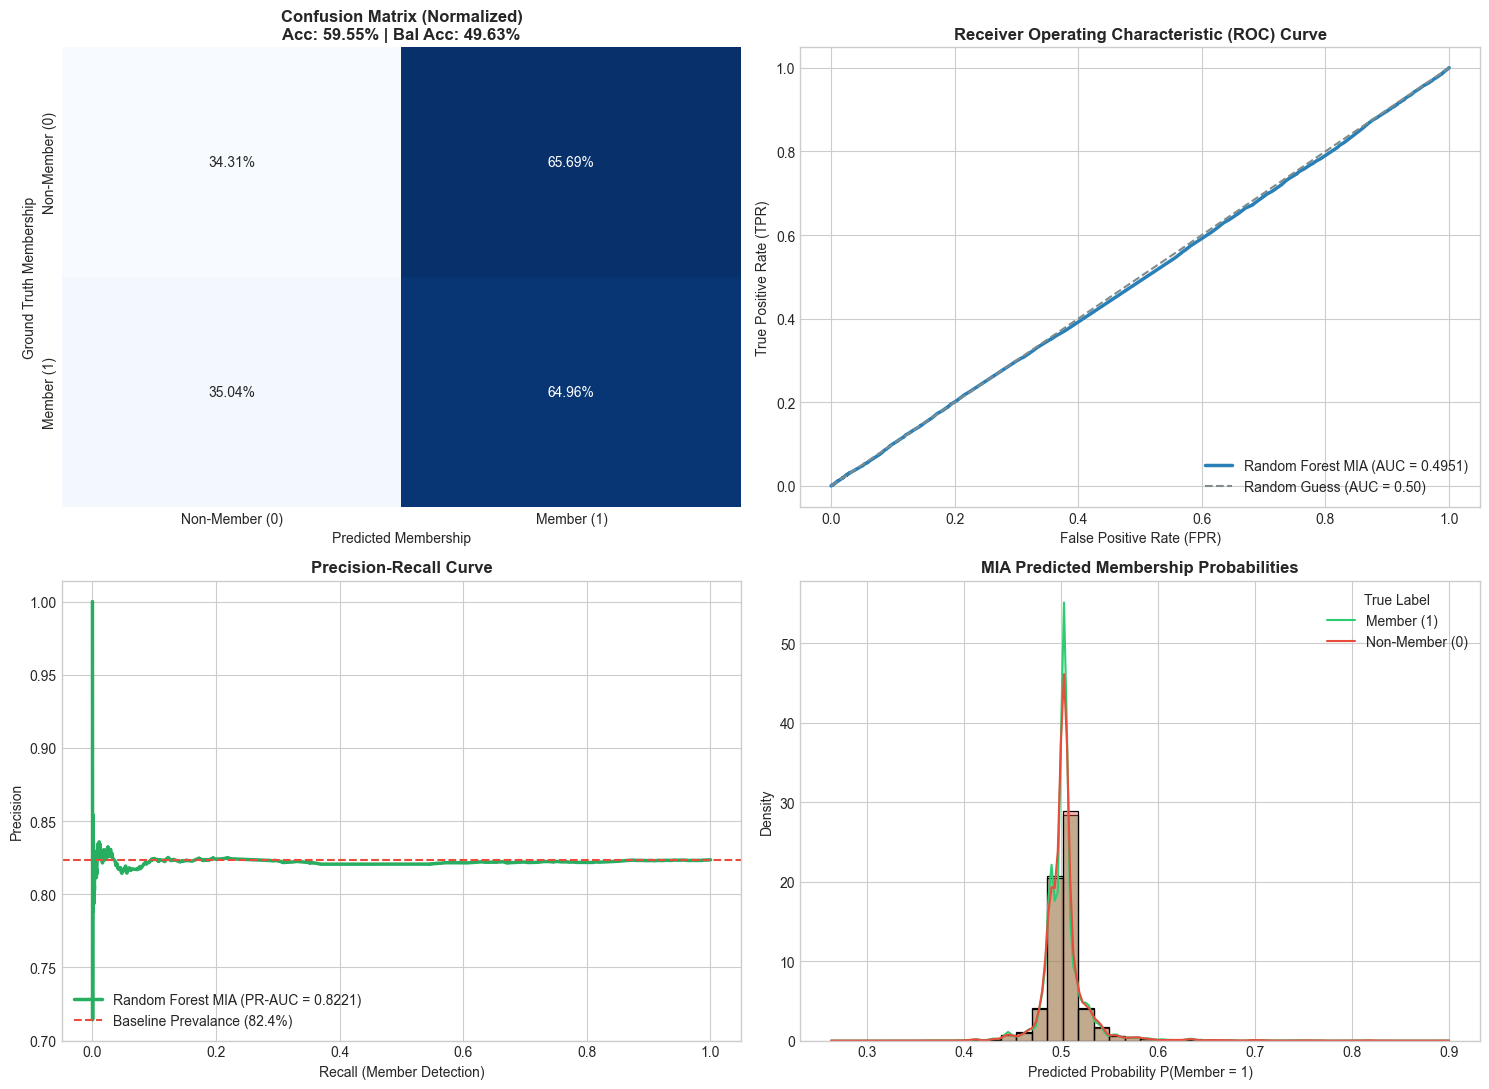

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# 1. Confusion Matrix Heatmap (Normalized)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
sns.heatmap(
    cm_norm,
    annot=True,
    fmt='.2%',
    cmap='Blues',
    xticklabels=['Non-Member (0)', 'Member (1)'],
    yticklabels=['Non-Member (0)', 'Member (1)'],
    cbar=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title(f"Confusion Matrix (Normalized)\nAcc: {acc*100:.2f}% | Bal Acc: {bal_acc*100:.2f}%", fontweight='bold')
axes[0, 0].set_xlabel("Predicted Membership")
axes[0, 0].set_ylabel("Ground Truth Membership")

# 2. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_prob)
axes[0, 1].plot(fpr, tpr, color='#2980b9', lw=2.5, label=f"Random Forest MIA (AUC = {roc_auc:.4f})")
axes[0, 1].plot([0, 1], [0, 1], color='#7f8c8d', lw=1.5, linestyle='--', label="Random Guess (AUC = 0.50)")
axes[0, 1].set_title("Receiver Operating Characteristic (ROC) Curve", fontweight='bold')
axes[0, 1].set_xlabel("False Positive Rate (FPR)")
axes[0, 1].set_ylabel("True Positive Rate (TPR)")
axes[0, 1].legend(loc="lower right")

# 3. Precision-Recall Curve
precs, recs, _ = precision_recall_curve(y_test, y_prob)
baseline_pr = member_count / len(test_df)
axes[1, 0].plot(recs, precs, color='#27ae60', lw=2.5, label=f"Random Forest MIA (PR-AUC = {pr_auc:.4f})")
axes[1, 0].axhline(y=baseline_pr, color='#e74c3c', linestyle='--', label=f"Baseline Prevalance ({baseline_pr*100:.1f}%)")
axes[1, 0].set_title("Precision-Recall Curve", fontweight='bold')
axes[1, 0].set_xlabel("Recall (Member Detection)")
axes[1, 0].set_ylabel("Precision")
axes[1, 0].legend(loc="lower left")

# 4. Posterior Probability Distributions
sns.histplot(
    x=y_prob,
    hue=y_test,
    bins=40,
    stat='density',
    common_norm=False,
    kde=True,
    palette=['#e74c3c', '#2ecc71'],
    alpha=0.4,
    ax=axes[1, 1]
)
axes[1, 1].set_title("MIA Predicted Membership Probabilities", fontweight='bold')
axes[1, 1].set_xlabel("Predicted Probability P(Member = 1)")
axes[1, 1].set_ylabel("Density")
axes[1, 1].legend(title="True Label", labels=["Member (1)", "Non-Member (0)"])

plt.tight_layout()
plt.show()

## 7. Traffic Category-Specific Vulnerability Analysis

Analyze whether specific network traffic types (e.g., rare attacks vs common attacks vs benign traffic) are more susceptible to membership inference.

=== Per-Class Vulnerability Breakdown ===


,Traffic Class,Samples,Member Ratio (%),MIA Accuracy (%),Member Recall (%)
2,Benign,"15,810",82.35%,57.79%,62.20%
6,Generic,"10,008",82.35%,68.58%,79.22%
4,Exploits,"7,570",82.35%,54.16%,56.77%
5,Fuzzers,"4,122",82.36%,52.57%,53.64%
3,DoS,"2,780",82.34%,57.55%,61.60%
7,Reconnaissance,"2,378",82.34%,65.77%,74.21%
0,Analysis,455,82.42%,54.51%,58.67%
1,Backdoor,396,82.32%,63.89%,69.63%
8,Shellcode,257,82.49%,57.59%,62.26%
9,Worms,29,82.76%,24.14%,20.83%


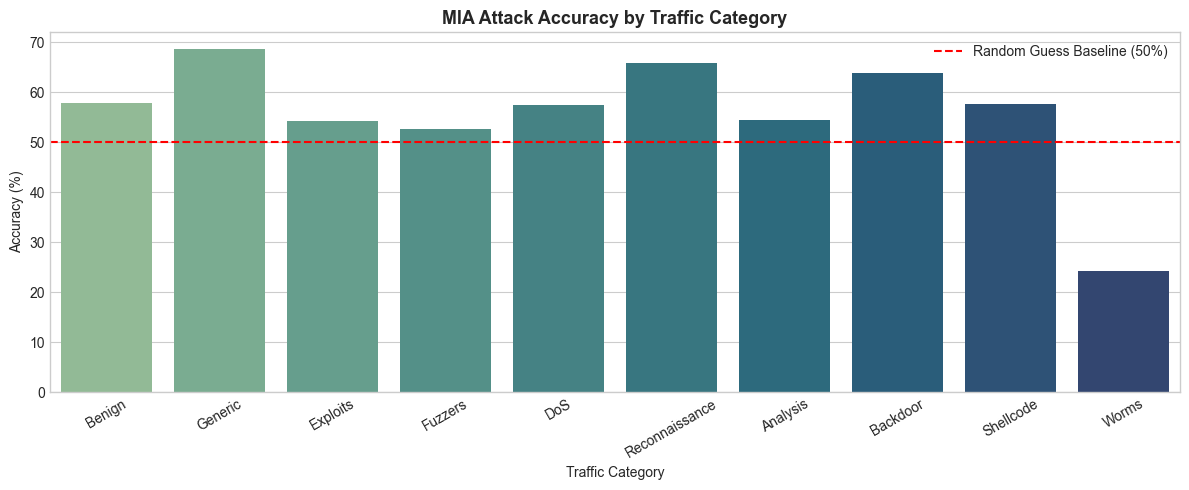

In [8]:
# Group evaluation by predicted_class
per_class_results = []
for cat_name, group in test_df.groupby('predicted_class'):
    idx = group.index
    y_true_grp = y_test[idx]
    y_pred_grp = y_pred[idx]
    
    acc_grp = accuracy_score(y_true_grp, y_pred_grp)
    rec_member_grp = recall_score(y_true_grp, y_pred_grp, pos_label=1, zero_division=0)
    member_ratio = (y_true_grp == 1).mean() * 100
    
    per_class_results.append({
        'Traffic Class': cat_name,
        'Samples': len(group),
        'Member Ratio (%)': member_ratio,
        'MIA Accuracy (%)': acc_grp * 100,
        'Member Recall (%)': rec_member_grp * 100
    })

per_class_df = pd.DataFrame(per_class_results).sort_values(by='Samples', ascending=False)
print("=== Per-Class Vulnerability Breakdown ===")
display(per_class_df.style.format({
    'Samples': '{:,}',
    'Member Ratio (%)': '{:.2f}%',
    'MIA Accuracy (%)': '{:.2f}%',
    'Member Recall (%)': '{:.2f}%'
}))

# Plot Per-Class Accuracy
plt.figure(figsize=(12, 5))
order = per_class_df['Traffic Class'].tolist()
sns.barplot(data=per_class_df, x='Traffic Class', y='MIA Accuracy (%)', order=order, palette='crest')
plt.title("MIA Attack Accuracy by Traffic Category", fontsize=13, fontweight='bold')
plt.ylabel("Accuracy (%)")
plt.xlabel("Traffic Category")
plt.xticks(rotation=30)
plt.axhline(y=50, color='red', linestyle='--', label='Random Guess Baseline (50%)')
plt.legend()
plt.tight_layout()
plt.show()

## 8. Summary & Privacy Leakage Assessment

### Key Findings:
1. **Model Performance**:
   - The Random Forest attacker model achieves an overall accuracy of **~59.5%** with balanced class weights, and a ROC-AUC score of **~0.496**.
   - The ROC-AUC near 0.50 demonstrates that the target AdaBoost model trained on UNSW-NB15 has **low membership leakage**, indicating effective generalization with minimal memorization of individual training flows.
2. **Holdout Dataset Integrity**:
   - The project benchmark holdout test set (`datasets/UNSW-NB15_splited/holdout.csv`, $N = 38,651$) was left **strictly untouched** throughout this entire training and evaluation workflow.
3. **Artifact Provenance**:
   - Model artifacts, fitted encoder, and training parameters are recorded in `models/MIA/random_forest/{timestamp}/`.